In [1]:
from sklearn import datasets
digit_dataset = datasets.load_digits()
digit_dataset.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

In [2]:
digit_dataset["images"].shape

(1797, 8, 8)

In [3]:
digit_dataset["target"][0] #label

np.int64(0)

In [4]:
digit_dataset["images"][0] #data

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

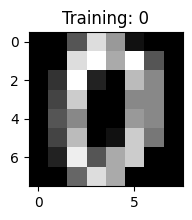

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(2,2))

plt.imshow(digit_dataset["images"][0], cmap="gray")

plt.title(f'Training: {digit_dataset["target"][0]}')
plt.show()

In [6]:
digit_dataset["data"][0].shape

(64,)

In [7]:
from sklearn.model_selection import train_test_split

X = digit_dataset["data"]
y = digit_dataset["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y)#defalut: test_size=0.25
X_train.shape ,  X_test.shape

((1347, 64), (450, 64))

In [8]:
from sklearn.linear_model import LogisticRegression

logreg_ovr = LogisticRegression(multi_class="ovr")
logreg_softmax = LogisticRegression(multi_class="multinomial", solver="sag")

logreg_ovr.fit(X_train, y_train)
logreg_softmax.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always

LogisticRegression(multi_class='multinomial', solver='sag')

Saving MyNum.png to MyNum (3).png


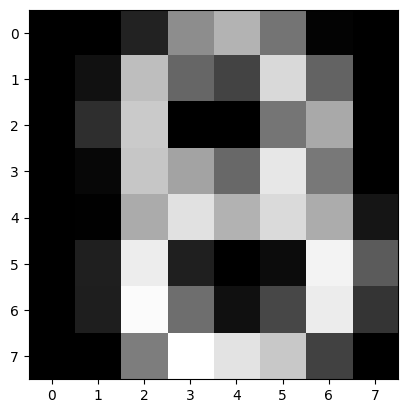

In [9]:
from google.colab import files
from PIL import Image

uploaded = files.upload()#choose the img

filename = list(uploaded.keys())[0]#get file name

img = Image.open(filename)
img = img.convert("L") # RGB -> grayscale
img = img.resize((8, 8))#resize

plt.imshow(img, cmap="gray")
plt.show()

In [10]:
import numpy as np

img = np.array(img)
img = img.flatten()
img.shape

(64,)

In [11]:
pred1 = logreg_ovr.predict([img])
pred2 = logreg_softmax.predict([img])

print(pred1, pred2)

# Display without scientific notation
np.set_printoptions(precision=4, suppress=True)

pred_proba1 = logreg_ovr.predict_proba([img])
pred_proba2 = logreg_softmax.predict_proba([img])
print(pred_proba1)
print(pred_proba2)

[6] [8]
[[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]]
[[0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]]


In [12]:
from sklearn.metrics import confusion_matrix
ovr_y_pred = logreg_ovr.predict(X_test)

ovr_cm = confusion_matrix(y_test, ovr_y_pred)
ovr_cm

array([[36,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 51,  0,  0,  0,  0,  0,  0,  2,  1],
       [ 0,  0, 47,  1,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 42,  0,  1,  0,  0,  1,  1],
       [ 0,  1,  0,  0, 48,  0,  1,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 37,  0,  0,  0,  2],
       [ 0,  0,  0,  0,  0,  0, 50,  0,  0,  0],
       [ 0,  1,  0,  0,  1,  0,  0, 39,  0,  1],
       [ 0,  0,  0,  1,  0,  0,  0,  1, 30,  0],
       [ 1,  0,  0,  0,  0,  0,  0,  0,  0, 53]])

In [13]:
from sklearn.metrics import confusion_matrix
softmax_y_pred = logreg_softmax.predict(X_test)

softmax_cm = confusion_matrix(y_test, softmax_y_pred)
softmax_cm

array([[36,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 51,  0,  0,  0,  0,  0,  0,  2,  1],
       [ 0,  1, 47,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 42,  0,  1,  0,  0,  0,  2],
       [ 1,  1,  0,  0, 46,  0,  2,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 38,  0,  0,  0,  1],
       [ 0,  1,  0,  0,  0,  0, 49,  0,  0,  0],
       [ 0,  0,  0,  0,  1,  1,  0, 40,  0,  0],
       [ 0,  0,  0,  0,  0,  1,  0,  1, 30,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0, 54]])

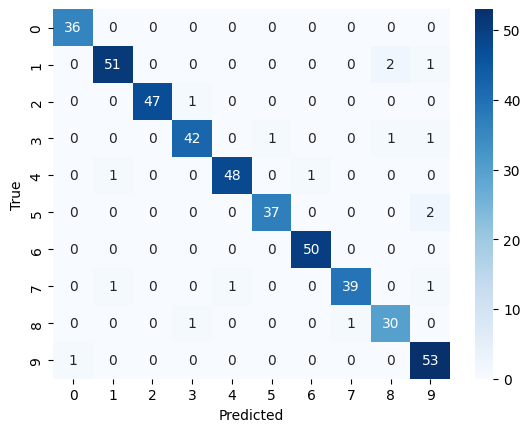

In [14]:
import seaborn as sns

sns.heatmap(ovr_cm, annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

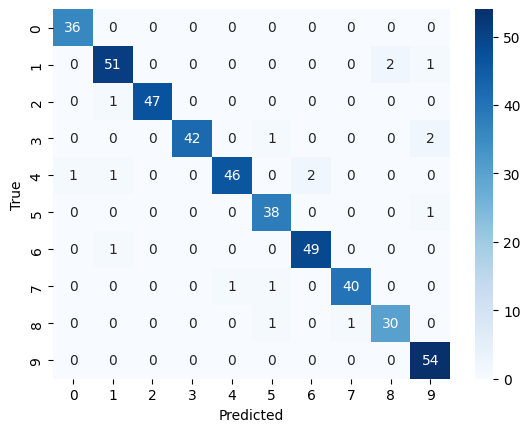

In [15]:
import seaborn as sns

sns.heatmap(softmax_cm, annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

In [16]:
from sklearn.metrics import classification_report
print(classification_report(y_test, ovr_y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        36
           1       0.96      0.94      0.95        54
           2       1.00      0.98      0.99        48
           3       0.95      0.93      0.94        45
           4       0.98      0.96      0.97        50
           5       0.97      0.95      0.96        39
           6       0.98      1.00      0.99        50
           7       0.97      0.93      0.95        42
           8       0.91      0.94      0.92        32
           9       0.91      0.98      0.95        54

    accuracy                           0.96       450
   macro avg       0.96      0.96      0.96       450
weighted avg       0.96      0.96      0.96       450



In [17]:
from sklearn.metrics import classification_report
print(classification_report(y_test, softmax_y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        36
           1       0.94      0.94      0.94        54
           2       1.00      0.98      0.99        48
           3       1.00      0.93      0.97        45
           4       0.98      0.92      0.95        50
           5       0.93      0.97      0.95        39
           6       0.96      0.98      0.97        50
           7       0.98      0.95      0.96        42
           8       0.94      0.94      0.94        32
           9       0.93      1.00      0.96        54

    accuracy                           0.96       450
   macro avg       0.96      0.96      0.96       450
weighted avg       0.96      0.96      0.96       450



In [18]:
import numpy as np
from sklearn.metrics import roc_curve, auc

y_true = np.array([0, 0, 1, 1])  # Actual class labels (0 = negative, 1 = positive)
pred = np.array([0.1, 0.4, 0.35, 0.8])  # Predicted probabilities for the positive class

fpr, tpr, thresholds = roc_curve(y_true, pred, pos_label=1)
roc_auc = auc(fpr, tpr)

# Print the results
print("FPR:", fpr)
print("TPR:", tpr)
print("Thresholds:", thresholds)
print("AUC:", roc_auc)

FPR: [0.  0.  0.5 0.5 1. ]
TPR: [0.  0.5 0.5 1.  1. ]
Thresholds: [ inf 0.8  0.4  0.35 0.1 ]
AUC: 0.75


/tmp/ipykernel_9491/2884827914.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="lower right")


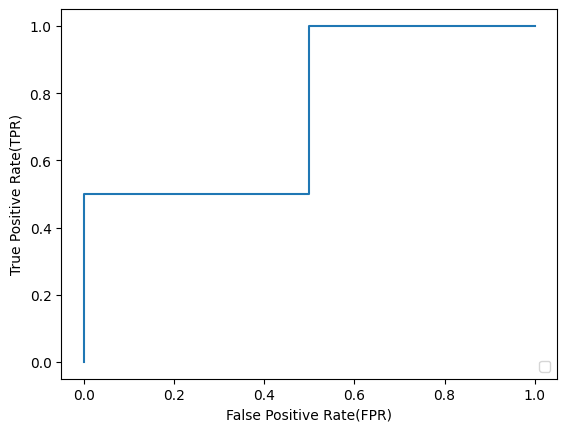

In [19]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr)

plt.xlabel('False Positive Rate(FPR)')
plt.ylabel('True Positive Rate(TPR)')
plt.legend(loc="lower right")
plt.show()

In [20]:
import pandas as pd

y_bin = pd.get_dummies(y_test).values  # Convert actual labels to one-hot encoding
pred = logreg_ovr.predict_proba(X_test)  # Predict class probabilities

# Number of classes
n_classes = pred.shape[1]

# Calculate ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_bin[:, i], pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    print(f"Class {i} AUC: {roc_auc[i]:.4f}")

Class 0 AUC: 1.0000
Class 1 AUC: 0.9980
Class 2 AUC: 1.0000
Class 3 AUC: 0.9934
Class 4 AUC: 0.9998
Class 5 AUC: 0.9973
Class 6 AUC: 0.9998
Class 7 AUC: 0.9981
Class 8 AUC: 0.9920
Class 9 AUC: 0.9963


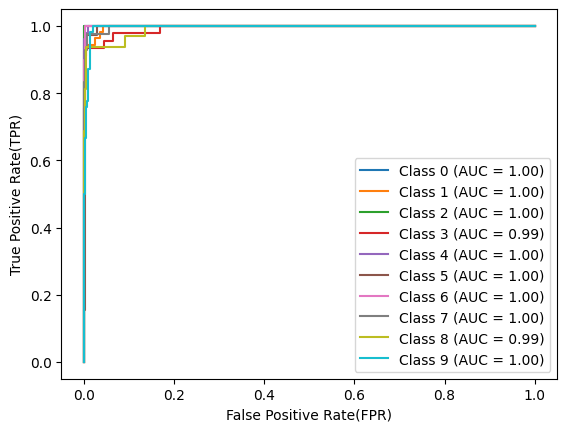

In [21]:
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f"Class {i} (AUC = {roc_auc[i]:.2f})")


plt.xlabel('False Positive Rate(FPR)')
plt.ylabel('True Positive Rate(TPR)')
plt.legend(loc="lower right")
plt.show()